# Step 07: regression
This notebook predicts the total recorded hours of each ICU patient from the information available at hour 7.

## Setup and input checks
This section sets up the helpers and paths and checks the split file against the earlier steps.

In [1]:
import contextlib
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
from scipy import stats
from sklearn.dummy import DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import PredefinedSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from tqdm import tqdm

SEED = 42
SEPTIC, CONTROL = "#d1495b", "#2e86ab"
N_PAT = 40336
SPLIT_N = {"train": 28235, "val": 6050, "test": 6051}
sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:.3f}".format
SUMMARY, SAVED = [], []
COUNT = {"pass": 0, "fail": 0}


def log(text=""):
    print(text)
    SUMMARY.append(str(text))


def check(label, ok, detail=""):
    ok = bool(ok)
    COUNT["pass" if ok else "fail"] += 1
    tail = f" ({detail})" if detail != "" else ""
    log(f"[{'PASS' if ok else 'FAIL'}] {label}{tail}")
    return ok


def expect(label, observed, expected, tol=0):
    return check(label, abs(observed - expected) <= tol, f"observed {observed}, expected {expected}")


@contextlib.contextmanager
def guarded(label):
    try:
        yield
    except Exception as e:
        check(label, False, f"{type(e).__name__}: {e}")


@contextlib.contextmanager
def timed(label):
    t0 = time.time()
    try:
        yield
    finally:
        log(f"{label}: {time.time() - t0:.1f} s")


def save_fig(name):
    plt.tight_layout()
    path = FIG / name
    plt.savefig(path, dpi=150)
    SAVED.append(path)
    plt.show()
    plt.close()


def save_csv(df, name):
    path = TAB / name
    df.to_csv(path, index=False)
    SAVED.append(path)
    log(f"saved {name} ({len(df)} rows)")


def stop_if(cond, msg):
    if cond:
        raise RuntimeError(msg)


def find_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "dataset").is_dir():
            return p
    raise FileNotFoundError(f"no folder with a dataset directory above {here}")


ROOT = find_root()
PROC, TAB, FIG = ROOT / "data" / "processed", ROOT / "results" / "tables", ROOT / "results" / "figures"
for d in (TAB, FIG):
    d.mkdir(parents=True, exist_ok=True)
log(f"root: {ROOT}")

f0 = COUNT["fail"]
with open(PROC / "core_features.json") as fh:
    core = json.load(fh)["core"]
ps = pd.read_csv(PROC / "patient_splits.csv", dtype={"patient_id": str, "hospital": str})
ps["ever_septic"] = ps["ever_septic"].astype(int)

with guarded("split file checks"):
    expect("unique patients", ps["patient_id"].nunique(), N_PAT)
    expect("rows in split file", len(ps), N_PAT)
    sizes = ps["split"].value_counts().to_dict()
    for s, n in SPLIT_N.items():
        expect(f"{s} patients", sizes.get(s, 0), n)
    check("cv_fold is -1 exactly for test", ((ps["cv_fold"] == -1) == (ps["split"] == "test")).all())
    expect("minimum n_rows", ps["n_rows"].min(), 8)

STATIC_EXTRA = [c for c in ["HospAdmTime", "ICULOS", "unit_1", "unit_2", "unit_unknown", "Age", "Gender"] if c not in core]
PRED = core + STATIC_EXTRA
log(f"core features: {len(core)}, extra static: {len(STATIC_EXTRA)}, predictors: {len(PRED)}")
stop_if(COUNT["fail"] > f0, "input checks failed, the later sections depend on them")

root: /Users/harnoorkaur/Downloads/Sepsis_ml
[PASS] unique patients (observed 40336, expected 40336)
[PASS] rows in split file (observed 40336, expected 40336)
[PASS] train patients (observed 28235, expected 28235)
[PASS] val patients (observed 6050, expected 6050)
[PASS] test patients (observed 6051, expected 6051)
[PASS] cv_fold is -1 exactly for test
[PASS] minimum n_rows (observed 8, expected 8)
core features: 50, extra static: 5, predictors: 55


## Hour-7 table
This section reads only the hour 7 rows from the feature file and attaches the stay length and split information.

In [2]:
FEAT = PROC / "features_flat.parquet"
f0 = COUNT["fail"]
names = pq.read_schema(FEAT).names
missing = [c for c in ["patient_id", "hour"] + PRED if c not in names]
check("predictors exist in features_flat", not missing, f"missing: {missing[:5]}")
stop_if(missing, "predictors missing from features_flat, cannot build the hour 7 table")

with timed("read hour 7 rows"):
    h7 = pq.read_table(FEAT, columns=["patient_id", "hour"] + PRED, filters=[("hour", "==", 7)]).to_pandas()
with timed("count rows per patient"):
    rows_per = pq.read_table(FEAT, columns=["patient_id"]).to_pandas()["patient_id"].astype(str).value_counts()

h7["patient_id"] = h7["patient_id"].astype(str)
keep_cols = ["patient_id", "hospital", "split", "cv_fold", "ever_septic", "n_rows", "first_iculos"]
tab = h7.merge(ps[keep_cols], on="patient_id", how="left", validate="one_to_one")
tab["y_log"] = np.log1p(tab["n_rows"])

with guarded("hour 7 table checks"):
    expect("rows in hour 7 table", len(tab), N_PAT)
    check("one row per patient", tab["patient_id"].is_unique)
    check("hour is 7 everywhere", (tab["hour"] == 7).all())
    sizes = tab["split"].value_counts().to_dict()
    for s, n in SPLIT_N.items():
        expect(f"{s} patients in table", sizes.get(s, 0), n)
    counted = rows_per.reindex(tab["patient_id"]).to_numpy()
    check("n_rows equals row count in features_flat", (counted == tab["n_rows"].to_numpy()).all())
    check("target has no NaN", tab["y_log"].notna().all())
stop_if(COUNT["fail"] > f0, "hour 7 table checks failed, the later sections depend on it")

tab.to_parquet(PROC / "reg_table_hour7.parquet", index=False)
SAVED.append(PROC / "reg_table_hour7.parquet")
for key in ["split", "ever_septic"]:
    log(f"n_rows by {key}")
    log(tab.groupby(key)["n_rows"].agg(["count", "mean", "median", "max"]).to_string())

[PASS] predictors exist in features_flat (missing: [])
read hour 7 rows: 0.2 s
count rows per patient: 0.0 s
[PASS] rows in hour 7 table (observed 40336, expected 40336)
[PASS] one row per patient
[PASS] hour is 7 everywhere
[PASS] train patients in table (observed 28235, expected 28235)
[PASS] val patients in table (observed 6050, expected 6050)
[PASS] test patients in table (observed 6051, expected 6051)
[PASS] n_rows equals row count in features_flat
[PASS] target has no NaN
n_rows by split
       count   mean  median  max
split                           
test    6051 38.376  38.000  336
train  28235 38.461  39.000  336
val     6050 38.684  39.000  336
n_rows by ever_septic
             count   mean  median  max
ever_septic                           
0            37404 36.889  39.000  336
1             2932 58.803  37.500  336


## Pre-processing for regression
Medians, the skew rule and the scaling are fitted on train patients only. The same parameters are then applied to validation and test.

In [3]:
MASK = {s: tab["split"].eq(s).to_numpy() for s in SPLIT_N}
y = tab["y_log"].to_numpy()
y_train, y_val, y_test = (y[MASK[s]] for s in ["train", "val", "test"])


def clean(v):
    v = np.array(v, dtype=float)
    v[~np.isfinite(v)] = np.nan
    return v


def slog(v):
    return np.sign(v) * np.log1p(np.abs(v))


def fit_params(df, cols):
    par = {}
    for c in cols:
        v = clean(df[c])
        ok = v[~np.isnan(v)]
        if set(np.unique(ok)) <= {0.0, 1.0}:
            fill = float(ok.mean() >= 0.5) if len(ok) else 0.0
            par[c] = dict(binary=True, fill=fill, log=False, skew=np.nan, mean=0.0, std=1.0, const=False)
            continue
        med = float(np.median(ok))
        f = np.where(np.isnan(v), med, v)
        sd0 = f.std()
        skew = float(stats.skew(f)) if sd0 > 1e-12 else 0.0
        lg = abs(skew) > 3
        if lg:
            f = slog(f)
        sd = float(f.std())
        par[c] = dict(binary=False, fill=med, log=lg, skew=skew, mean=float(f.mean()),
                      std=sd if sd > 1e-12 else 1.0, const=sd <= 1e-12)
    return par


def transform(df, par):
    cols = list(par)
    out = np.empty((len(df), len(cols)))
    for j, c in enumerate(cols):
        p = par[c]
        v = clean(df[c])
        v = np.where(np.isnan(v), p["fill"], v)
        if not p["binary"]:
            if p["log"]:
                v = slog(v)
            v = (v - p["mean"]) / p["std"]
        out[:, j] = v
    return out


with timed("fit pre-processing on train"):
    PAR = fit_params(tab[MASK["train"]], PRED)
    X_train, X_val, X_test = (transform(tab[MASK[s]], PAR) for s in ["train", "val", "test"])

joblib.dump({"cols": PRED, "params": PAR, "hour": 7, "target": "log1p(n_rows)", "skew_cut": 3},
            PROC / "reg_scale_params.joblib")
SAVED.append(PROC / "reg_scale_params.joblib")

is_std = np.array([not PAR[c]["binary"] and not PAR[c]["const"] for c in PRED])
with guarded("pre-processing checks"):
    for nm, X in [("train", X_train), ("val", X_val), ("test", X_test)]:
        check(f"X_{nm} has no NaN or inf", np.isfinite(X).all(), str(X.shape))
    expect("train mean of standardised columns", float(np.abs(X_train[:, is_std].mean(0)).max()), 0, 1e-3)
    expect("train std of standardised columns", float(np.abs(X_train[:, is_std].std(0) - 1).max()), 0, 1e-3)

n_bin = sum(PAR[c]["binary"] for c in PRED)
log(f"predictors: {len(PRED)}, binary: {n_bin}, constant in train: {sum(PAR[c]['const'] for c in PRED)}")
log(f"log-transformed columns: {sum(PAR[c]['log'] for c in PRED)}")

fit pre-processing on train: 0.1 s
[PASS] X_train has no NaN or inf ((28235, 55))
[PASS] X_val has no NaN or inf ((6050, 55))
[PASS] X_test has no NaN or inf ((6051, 55))
[PASS] train mean of standardised columns (observed 4.583359251425077e-15, expected 0)
[PASS] train std of standardised columns (observed 2.220446049250313e-16, expected 0)
predictors: 55, binary: 4, constant in train: 0
log-transformed columns: 8


## Single best predictor
Every predictor is correlated with the log stay on train patients. The top five list skips predictors that are too close to one already chosen.

In [4]:
IDX = {c: i for i, c in enumerate(PRED)}


def corr_with(X, t):
    Xc, tc = X - X.mean(0), t - t.mean()
    den = np.sqrt((Xc ** 2).sum(0) * (tc ** 2).sum())
    return np.divide(Xc.T @ tc, den, out=np.zeros(X.shape[1]), where=den > 0)


pear = corr_with(X_train, y_train)
spear = corr_with(pd.DataFrame(X_train).rank().to_numpy(), pd.Series(y_train).rank().to_numpy())
ranking = pd.DataFrame({"predictor": PRED, "pearson": pear, "spearman": spear})
ranking["abs_pearson"] = ranking["pearson"].abs()
ranking = ranking.sort_values("abs_pearson", ascending=False).reset_index(drop=True)
save_csv(ranking, "regression_single_predictor_ranking.csv")
log(ranking.head(10).to_string(index=False))

BEST_PRED = ranking["predictor"].iloc[0]
TOP5 = []
for c in ranking["predictor"]:
    ok = all(abs(np.corrcoef(X_train[:, IDX[c]], X_train[:, IDX[k]])[0, 1]) < 0.8 for k in TOP5)
    if ok:
        TOP5.append(c)
    if len(TOP5) == 5:
        break
log(f"best single predictor: {BEST_PRED}")
log(f"top 5 for polynomial models: {TOP5}")
check("five polynomial predictors found", len(TOP5) == 5, f"{len(TOP5)} found")

saved regression_single_predictor_ranking.csv (55 rows)
     predictor  pearson  spearman  abs_pearson
      FiO2_tsl   -0.114    -0.110        0.114
   cnt_Lactate    0.102     0.100        0.102
     PaCO2_tsl   -0.101    -0.102        0.101
  n_labs_last6    0.093     0.086        0.093
 n_labs_so_far    0.089     0.089        0.089
      cnt_FiO2    0.078     0.092        0.078
     EtCO2_tsl   -0.078    -0.073        0.078
     cnt_PaCO2    0.072     0.089        0.072
         O2Sat    0.069     0.063        0.069
Fibrinogen_tsl   -0.065    -0.067        0.065
best single predictor: FiO2_tsl
top 5 for polynomial models: ['FiO2_tsl', 'cnt_Lactate', 'PaCO2_tsl', 'n_labs_last6', 'EtCO2_tsl']
[PASS] five polynomial predictors found (5 found)


True

## Models
All models are fitted on train patients. Ridge and Lasso alphas come from 5-fold cross-validation with the saved train folds.

In [5]:
ALL_IDX = list(range(len(PRED)))
folds_train = tab.loc[MASK["train"], "cv_fold"].to_numpy()
check("train folds are 0 to 4", sorted(np.unique(folds_train).tolist()) == [0, 1, 2, 3, 4])


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


def cv_scan(make, alphas, X, t, folds):
    ps_ = PredefinedSplit(folds)
    rows = []
    for a in tqdm(alphas, leave=False):
        errs = []
        for tr_i, te_i in ps_.split():
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", ConvergenceWarning)
                m = make(a).fit(X[tr_i], t[tr_i])
            errs.append(rmse(t[te_i], m.predict(X[te_i])))
        rows.append(dict(alpha=a, cv_rmse_log=np.mean(errs), cv_rmse_std=np.std(errs)))
    return pd.DataFrame(rows)


def make_ridge(a):
    return Ridge(alpha=a, random_state=SEED)


def make_lasso(a):
    return Lasso(alpha=a, max_iter=10000, random_state=SEED)


def poly_model(degree):
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression())


best_i, top5_i = [IDX[BEST_PRED]], [IDX[c] for c in TOP5]
MODELS, N_IN = {}, {}


def add(name, model, idx, n_in):
    MODELS[name] = (model.fit(X_train[:, idx], y_train), idx)
    N_IN[name] = n_in


with timed("fit simple models"):
    add("baseline", DummyRegressor(strategy="median"), best_i, 0)
    add("simple_linear", LinearRegression(), best_i, 1)
    add("multiple_linear", LinearRegression(), ALL_IDX, len(PRED))
    add("poly2", poly_model(2), top5_i, 5)
    add("poly3", poly_model(3), top5_i, 5)

ridge_grid, lasso_grid = np.logspace(-2, 4, 13), np.logspace(-4, -0.5, 12)
with timed("cross-validation for ridge"):
    cv_ridge = cv_scan(make_ridge, ridge_grid, X_train, y_train, folds_train)
with timed("cross-validation for lasso"):
    cv_lasso = cv_scan(make_lasso, lasso_grid, X_train, y_train, folds_train)
ALPHA = {"ridge": float(cv_ridge.loc[cv_ridge["cv_rmse_log"].idxmin(), "alpha"]),
         "lasso": float(cv_lasso.loc[cv_lasso["cv_rmse_log"].idxmin(), "alpha"])}

with timed("fit ridge and lasso"):
    add("ridge", make_ridge(ALPHA["ridge"]), ALL_IDX, len(PRED))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        add("lasso", make_lasso(ALPHA["lasso"]), ALL_IDX, len(PRED))

cv_all = pd.concat([cv_ridge.assign(model="ridge"), cv_lasso.assign(model="lasso")])[
    ["model", "alpha", "cv_rmse_log", "cv_rmse_std"]]
save_csv(cv_all, "regression_cv_alpha.csv")
n_nz = int((MODELS["lasso"][0].coef_ != 0).sum())
log(f"chosen ridge alpha: {ALPHA['ridge']:.4g}, chosen lasso alpha: {ALPHA['lasso']:.4g}")
log(f"non-zero lasso coefficients: {n_nz} of {len(PRED)}")
check("lasso keeps at least one coefficient", n_nz > 0)
with guarded("train predictions are finite"):
    for nm, (m, idx) in MODELS.items():
        check(f"{nm} train predictions finite", np.isfinite(m.predict(X_train[:, idx])).all())

[PASS] train folds are 0 to 4
fit simple models: 0.1 s


cross-validation for ridge: 0.3 s


cross-validation for lasso: 1.1 s
fit ridge and lasso: 0.1 s
saved regression_cv_alpha.csv (25 rows)
chosen ridge alpha: 316.2, chosen lasso alpha: 0.0001
non-zero lasso coefficients: 53 of 55
[PASS] lasso keeps at least one coefficient
[PASS] baseline train predictions finite
[PASS] simple_linear train predictions finite
[PASS] multiple_linear train predictions finite
[PASS] poly2 train predictions finite
[PASS] poly3 train predictions finite
[PASS] ridge train predictions finite
[PASS] lasso train predictions finite


## Evaluation
Errors are reported in hours after clipping predictions at 8 hours. The best model is picked on validation and the test patients are scored once afterwards.

In [6]:
LOW = np.log1p(8)


def clip_log(p):
    return np.maximum(p, LOW)


def metrics(y_log_true, y_log_pred):
    p = clip_log(y_log_pred)
    t_h, p_h = np.expm1(y_log_true), np.expm1(p)
    res = t_h - p_h
    r2 = lambda a, b: 1 - np.sum((a - b) ** 2) / np.sum((a - a.mean()) ** 2)
    pear_h = np.corrcoef(t_h, p_h)[0, 1] if p_h.std() > 0 else np.nan
    return dict(rmse_h=float(np.sqrt(np.mean(res ** 2))), mae_h=float(np.mean(np.abs(res))),
                r2_h=float(r2(t_h, p_h)), pearson_h=float(pear_h),
                rmse_log=rmse(y_log_true, p), r2_log=float(r2(y_log_true, p)))


def predict_log(name, X):
    m, idx = MODELS[name]
    return m.predict(X[:, idx])


def score_table(X, t):
    rows = [dict(model=nm, n_inputs=N_IN[nm], **metrics(t, predict_log(nm, X))) for nm in MODELS]
    return pd.DataFrame(rows)


PL = {"val": {nm: predict_log(nm, X_val) for nm in MODELS}}
res_val = score_table(X_val, y_val)
save_csv(res_val, "regression_results_val.csv")
log(res_val.to_string(index=False))
BEST = res_val.sort_values("rmse_log").iloc[0]["model"]
log(f"best model on validation (rmse_log): {BEST}")
BEST_LOGGED = True

saved regression_results_val.csv (7 rows)
          model  n_inputs  rmse_h  mae_h   r2_h  pearson_h  rmse_log  r2_log
       baseline         0  23.407 13.495 -0.000        NaN     0.494  -0.067
  simple_linear         1  23.656 13.954 -0.022      0.129     0.475   0.014
multiple_linear        55  23.368 13.656  0.003      0.193     0.469   0.036
          poly2         5  23.492 13.857 -0.007      0.173     0.473   0.023
          poly3         5  23.506 13.858 -0.009      0.167     0.473   0.022
          ridge        55  23.369 13.653  0.003      0.193     0.469   0.036
          lasso        55  23.367 13.654  0.003      0.193     0.469   0.036
best model on validation (rmse_log): ridge


In [7]:
check("best model logged before test scoring", BEST_LOGGED)
PL["test"] = {nm: predict_log(nm, X_test) for nm in MODELS}
res_test = score_table(X_test, y_test)
save_csv(res_test, "regression_results_test.csv")
log(res_test.to_string(index=False))
log("test scored once")

pred_parts = []
for s in ["val", "test"]:
    part = tab.loc[MASK[s], ["patient_id", "split", "hospital", "ever_septic", "n_rows"]].reset_index(drop=True)
    for nm in MODELS:
        part[f"pred_hours_{nm}"] = np.expm1(clip_log(PL[s][nm]))
    pred_parts.append(part)
preds = pd.concat(pred_parts, ignore_index=True)
save_csv(preds, "regression_predictions.csv")

[PASS] best model logged before test scoring
saved regression_results_test.csv (7 rows)
          model  n_inputs  rmse_h  mae_h   r2_h  pearson_h  rmse_log  r2_log
       baseline         0  22.633 13.297 -0.001        NaN     0.491  -0.075
  simple_linear         1  22.858 13.673 -0.021      0.118     0.470   0.018
multiple_linear        55  22.525 13.314  0.009      0.203     0.461   0.051
          poly2         5  22.751 13.553 -0.011      0.152     0.467   0.027
          poly3         5  22.754 13.537 -0.011      0.150     0.467   0.028
          ridge        55  22.527 13.315  0.009      0.203     0.461   0.051
          lasso        55  22.526 13.314  0.009      0.203     0.461   0.051
test scored once
saved regression_predictions.csv (12101 rows)


Sensitivity check on validation: the same models without the two time-in-hospital columns.

In [8]:
drop = {"ICULOS", "HospAdmTime"}
keep_i = [i for i, c in enumerate(PRED) if c not in drop]
with guarded("sensitivity check"):
    lin = LinearRegression().fit(X_train[:, keep_i], y_train)
    cv_s = cv_scan(make_ridge, ridge_grid, X_train[:, keep_i], y_train, folds_train)
    a_s = float(cv_s.loc[cv_s["cv_rmse_log"].idxmin(), "alpha"])
    rdg = make_ridge(a_s).fit(X_train[:, keep_i], y_train)
    sens = []
    for nm, m in [("multiple_linear", lin), ("ridge", rdg)]:
        w = metrics(y_val, m.predict(X_val[:, keep_i]))
        full = res_val.set_index("model").loc[nm]
        sens.append(dict(model=nm, with_icu_time_rmse_log=full["rmse_log"], without_rmse_log=w["rmse_log"],
                         with_r2_log=full["r2_log"], without_r2_log=w["r2_log"]))
    sens = pd.DataFrame(sens)
    save_csv(sens, "regression_sensitivity_no_icu_time.csv")
    log(sens.to_string(index=False))
    log(f"ridge alpha without icu time columns: {a_s:.4g}")

saved regression_sensitivity_no_icu_time.csv (2 rows)
          model  with_icu_time_rmse_log  without_rmse_log  with_r2_log  without_r2_log
multiple_linear                   0.469             0.470        0.036           0.034
          ridge                   0.469             0.470        0.036           0.035
ridge alpha without icu time columns: 316.2


## Link to the main problem
The best model is checked against ever_septic and hospital. The stay length is not a sepsis label, so the AUROC here is only for information.

In [9]:
def summ(d, split, gtype, g):
    return dict(split=split, group_type=gtype, group=g, n=len(d), mean_actual_h=d["n_rows"].mean(),
                median_actual_h=d["n_rows"].median(), mean_pred_h=d["pred_h"].mean(),
                median_pred_h=d["pred_h"].median(), mean_resid_h=d["resid"].mean(),
                rmse_h=float(np.sqrt((d["resid"] ** 2).mean())), auroc_ever_septic=np.nan)


by_rows = []
with guarded("group summaries"):
    for s in ["val", "test"]:
        d = tab.loc[MASK[s], ["hospital", "ever_septic", "n_rows"]].reset_index(drop=True)
        d["plog"] = clip_log(PL[s][BEST])
        d["pred_h"] = np.expm1(d["plog"])
        d["resid"] = d["n_rows"] - d["pred_h"]
        top = summ(d, s, "all", "all")
        top["auroc_ever_septic"] = roc_auc_score(d["ever_septic"], d["plog"])
        by_rows.append(top)
        for key in ["ever_septic", "hospital"]:
            for g, sub in d.groupby(key):
                by_rows.append(summ(sub, s, key, g))
    by_group = pd.DataFrame(by_rows)
    save_csv(by_group, "regression_by_group.csv")
    log(by_group.to_string(index=False))

coef_rows = []
with guarded("coefficient table"):
    for nm in ["multiple_linear", "ridge", "lasso"]:
        co = pd.Series(MODELS[nm][0].coef_, index=PRED)
        for c in co.abs().sort_values(ascending=False).index[:12]:
            coef_rows.append(dict(model=nm, predictor=c, coefficient=co[c]))
    coefs = pd.DataFrame(coef_rows)
    save_csv(coefs, "regression_coefficients.csv")
    log(coefs[coefs["model"] == "multiple_linear"].head(8).to_string(index=False))

saved regression_by_group.csv (10 rows)
split  group_type group    n  mean_actual_h  median_actual_h  mean_pred_h  median_pred_h  mean_resid_h  rmse_h  auroc_ever_septic
  val         all   all 6050         38.684           39.000       34.408         33.831         4.276  23.369              0.693
  val ever_septic     0 5610         37.047           39.000       34.200         33.682         2.847  16.060                NaN
  val ever_septic     1  440         59.550           38.500       37.052         36.847        22.498  64.966                NaN
  val    hospital     A 3050         38.912           39.000       34.772         34.204         4.140  21.381                NaN
  val    hospital     B 3000         38.452           38.000       34.037         33.434         4.415  25.230                NaN
 test         all   all 6051         38.376           38.000       34.375         33.863         4.001  22.527              0.686
 test ever_septic     0 5611         36.734       

## Figures
Four figures: predictions against actual hours, residuals, the alpha search and the model comparison.

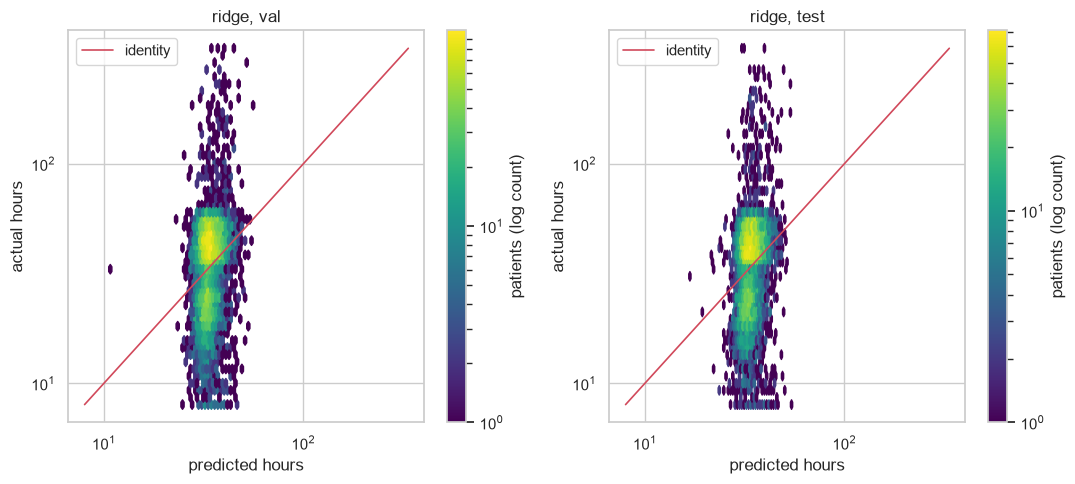

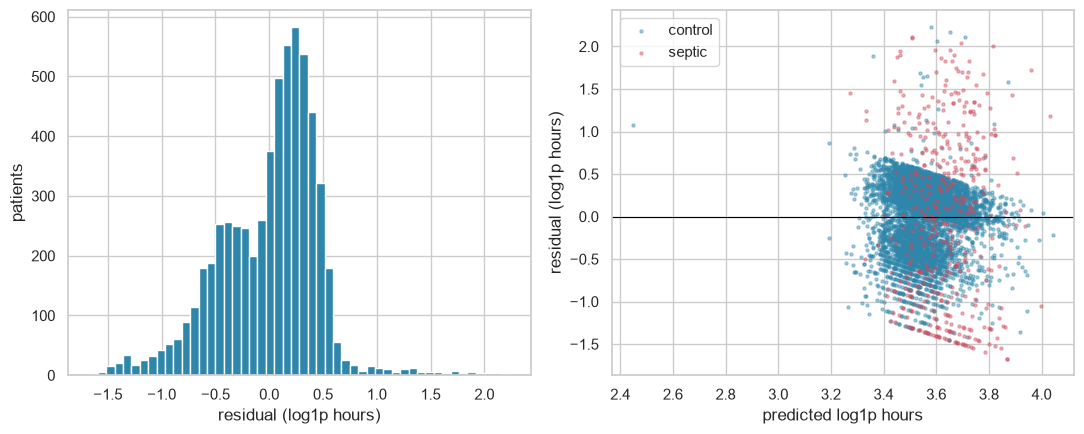

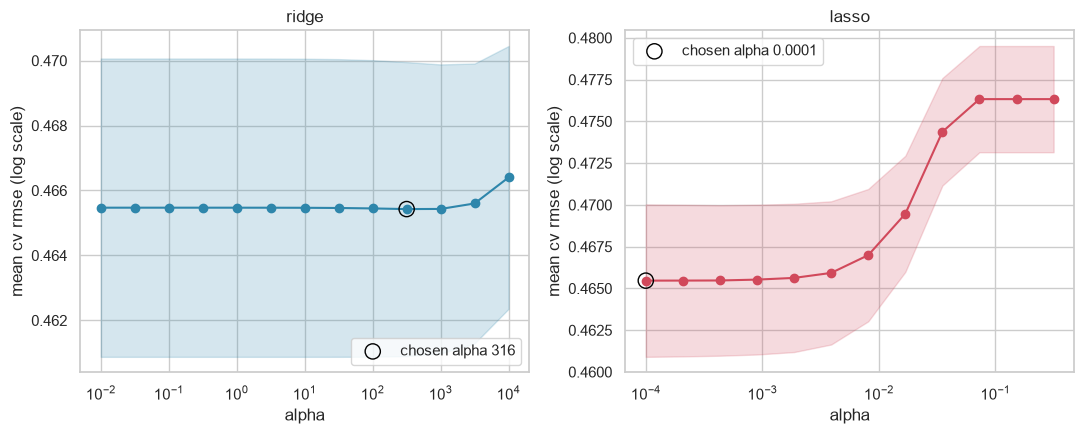

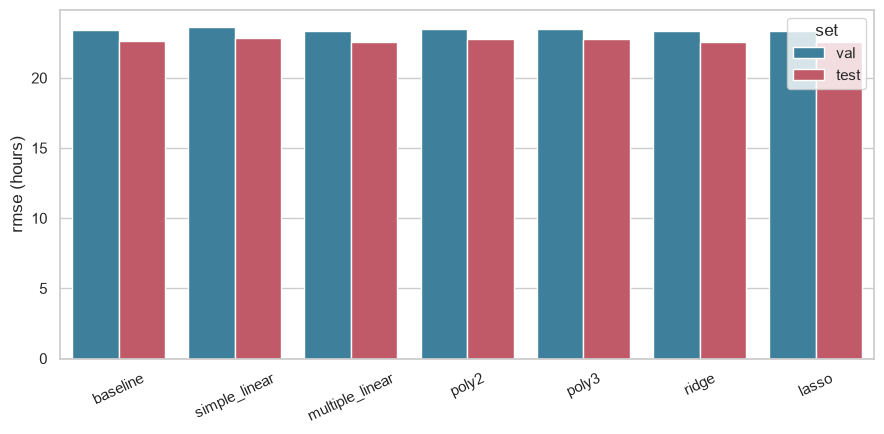

In [10]:
with guarded("fig07_pred_vs_actual"):
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, s in zip(axes, ["val", "test"]):
        act = tab.loc[MASK[s], "n_rows"].to_numpy()
        prd = np.expm1(clip_log(PL[s][BEST]))
        hb = ax.hexbin(prd, act, gridsize=45, xscale="log", yscale="log", bins="log", mincnt=1, cmap="viridis")
        top = max(act.max(), prd.max())
        ax.plot([8, top], [8, top], color=SEPTIC, lw=1.2, label="identity")
        ax.set_xlabel("predicted hours")
        ax.set_ylabel("actual hours")
        ax.set_title(f"{BEST}, {s}")
        ax.legend(loc="upper left")
        fig.colorbar(hb, ax=ax, label="patients (log count)")
    save_fig("fig07_pred_vs_actual.png")

with guarded("fig07_residuals"):
    p_val = clip_log(PL["val"][BEST])
    r_val = y_val - p_val
    sep = tab.loc[MASK["val"], "ever_septic"].to_numpy() == 1
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    axes[0].hist(r_val, bins=50, color=CONTROL)
    axes[0].set_xlabel("residual (log1p hours)")
    axes[0].set_ylabel("patients")
    axes[1].scatter(p_val[~sep], r_val[~sep], s=5, alpha=0.4, color=CONTROL, label="control")
    axes[1].scatter(p_val[sep], r_val[sep], s=5, alpha=0.4, color=SEPTIC, label="septic")
    axes[1].axhline(0, color="black", lw=0.8)
    axes[1].set_xlabel("predicted log1p hours")
    axes[1].set_ylabel("residual (log1p hours)")
    axes[1].legend()
    save_fig("fig07_residuals.png")

with guarded("fig07_cv_alpha"):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, nm, col in zip(axes, ["ridge", "lasso"], [CONTROL, SEPTIC]):
        d = cv_all[cv_all["model"] == nm]
        ax.plot(d["alpha"], d["cv_rmse_log"], marker="o", color=col)
        ax.fill_between(d["alpha"], d["cv_rmse_log"] - d["cv_rmse_std"], d["cv_rmse_log"] + d["cv_rmse_std"],
                        color=col, alpha=0.2)
        hit = d[d["alpha"] == ALPHA[nm]]
        ax.scatter(hit["alpha"], hit["cv_rmse_log"], s=120, facecolors="none", edgecolors="black", zorder=5,
                   label=f"chosen alpha {ALPHA[nm]:.3g}")
        ax.set_xscale("log")
        ax.set_xlabel("alpha")
        ax.set_ylabel("mean cv rmse (log scale)")
        ax.set_title(nm)
        ax.legend()
    save_fig("fig07_cv_alpha.png")

with guarded("fig07_model_comparison"):
    comp = pd.concat([res_val.assign(set="val"), res_test.assign(set="test")])
    plt.figure(figsize=(9, 4.5))
    sns.barplot(data=comp, x="model", y="rmse_h", hue="set", palette={"val": CONTROL, "test": SEPTIC})
    plt.ylabel("rmse (hours)")
    plt.xlabel("")
    plt.xticks(rotation=25)
    save_fig("fig07_model_comparison.png")

## Output files
This section lists the files written by this notebook and writes the summary text.

In [11]:
EXPECTED = ([PROC / "reg_table_hour7.parquet", PROC / "reg_scale_params.joblib"]
            + [TAB / n for n in ["regression_single_predictor_ranking.csv", "regression_cv_alpha.csv",
                                 "regression_results_val.csv", "regression_results_test.csv",
                                 "regression_predictions.csv", "regression_sensitivity_no_icu_time.csv",
                                 "regression_by_group.csv", "regression_coefficients.csv"]]
            + [FIG / n for n in ["fig07_pred_vs_actual.png", "fig07_residuals.png", "fig07_cv_alpha.png",
                                 "fig07_model_comparison.png"]])
for p in EXPECTED:
    if p.exists():
        log(f"{p.relative_to(ROOT)}: {p.stat().st_size / 1e6:.2f} MB")
    else:
        log(f"{p.relative_to(ROOT)}: MISSING")
check("all expected files exist", all(p.exists() for p in EXPECTED))

log(f"checks: {COUNT['pass']} passed, {COUNT['fail']} failed")
SUMMARY_PATH = ROOT / "results" / "step07_summary.txt"
SUMMARY_PATH.write_text("\n".join(SUMMARY), encoding="utf-8")
print(SUMMARY_PATH)

data/processed/reg_table_hour7.parquet: 2.19 MB
data/processed/reg_scale_params.joblib: 0.00 MB
results/tables/regression_single_predictor_ranking.csv: 0.00 MB
results/tables/regression_cv_alpha.csv: 0.00 MB
results/tables/regression_results_val.csv: 0.00 MB
results/tables/regression_results_test.csv: 0.00 MB
results/tables/regression_predictions.csv: 1.62 MB
results/tables/regression_sensitivity_no_icu_time.csv: 0.00 MB
results/tables/regression_by_group.csv: 0.00 MB
results/tables/regression_coefficients.csv: 0.00 MB
results/figures/fig07_pred_vs_actual.png: 0.16 MB
results/figures/fig07_residuals.png: 0.15 MB
results/figures/fig07_cv_alpha.png: 0.10 MB
results/figures/fig07_model_comparison.png: 0.04 MB
[PASS] all expected files exist
checks: 33 passed, 0 failed
/Users/harnoorkaur/Downloads/Sepsis_ml/results/step07_summary.txt
